# Proyecto integrador · Módulo I
## Evolución de las primas, la suma asegurada expuesta y los siniestros de Responsabilidad Civil en México (2018–2025)

**Diplomado:** Métodos estadísticos y matemáticos para la ciencia de datos  
**Fuentes:** Comisión Nacional de Seguros y Fianzas (CNSF), archivos abiertos 33, 34 y 35.  
**Escenario de negocio:** una aseguradora ficticia solicita una radiografía de los segmentos de Responsabilidad Civil.  
**Equipo:** Ana Teresa Piña Cruz, Mariana Alvarado, Zuzuky Diaz Ramos, Ilse Hernández Ramos, Samantha Tavera Flores

### Pregunta general de investigación
**¿Qué tipos de seguros de Responsabilidad Civil concentran el mayor volumen de negocio, suma asegurada expuesta y siniestros en México, y cómo ha cambiado su importancia relativa entre 2018 y 2025?**

### Preguntas específicas de investigación
1. ¿Qué tipos de seguro de Responsabilidad Civil han registrado el mayor crecimiento en primas emitidas entre 2018 y 2025 y cuáles concentran la mayor participación en el mercado?
2. ¿En qué tipos de seguro se concentra la mayor suma asegurada expuesta y cómo ha evolucionado su distribución durante el periodo de estudio?
3. ¿Qué tipos de seguro concentran los mayores montos de siniestros y cómo se compara su participación en estos montos con su participación en las primas emitidas?

### Objetivo general
Caracterizar la evolución y concentración del ramo de Responsabilidad Civil en México entre 2018 y 2025, identificando los tipos de seguro que destacan por volumen y crecimiento de primas emitidas, suma asegurada expuesta y montos de siniestros, mediante un análisis descriptivo de datos públicos de la CNSF.

### Delimitación
Análisis descriptivo y exploratorio para 2018–2025. **No** es una evaluación causal, una tarificación actuarial ni una recomendación de suscripción. La columna `moneda` contiene varias categorías, por lo que la unidad de los importes publicados y su comparabilidad deben verificarse con las notas técnicas oficiales antes de presentar cifras agregadas como definitivas.

## 1. Fuentes, procedencia y unidad de observación

Los datos utilizados provienen de la Comisión Nacional de Seguros y Fianzas (CNSF). Los enlaces de descarga se encuentran en `data/raw/READ.txt`. Los archivos originales se conservan sin modificaciones.

- **33 — Emisión:** contiene información sobre las primas, comisiones y número de incisos, clasificada por año, moneda, forma de venta, giro, entidad, tipo y subtipo de seguro, y esquema.
- **34 — Suma asegurada:** contiene información sobre las sumas aseguradas y número de incisos, clasificada por año, giro, entidad, esquema, tipo y subtipo de seguro, y cobertura.
- **35 — Siniestros:** contiene información sobre el número y monto de siniestros, clasificada por año, moneda, forma de venta, giro, esquema, entidad, tipo de seguro, cobertura, causa y tipo de siniestro.

**Unidad de observación original:** cada fila representa un registro estadístico que agrupa información según las características de cada archivo, no una póliza, persona o siniestro individual.

**Unidad de observación final:** cada fila representará un tipo de seguro en un año determinado. Para ello, se homologarán los nombres de los tipos de seguro y se agrupará la información antes de integrar las tres bases.

La variable `cobertura` no se utilizará como llave de unión, debido a que puede tener significados diferentes entre los archivos 34 y 35.

El número de incisos se analizará por separado en cada base para evitar posibles duplicidades. Por su parte, la suma asegurada se utilizará como un indicador de exposición económica, considerando que puede incluir montos asociados a distintas coberturas.

In [ ]:
# Importamos las bibliotecas necesarias para el manejo de rutas,
# procesamiento de datos, operaciones numéricas y visualización.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# Identificamos la carpeta raíz del proyecto para evitar el uso
# de rutas absolutas y garantizar la reproducibilidad del análisis.

ROOT = next((carpeta for carpeta in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (carpeta / "data" / "raw").is_dir()
             and (carpeta / "notebooks").is_dir()), None)

if ROOT is None:
    raise FileNotFoundError("Abra este notebook desde la carpeta del proyecto.")


# Definimos las rutas de trabajo, separando los datos originales
# de las tablas procesadas y las visualizaciones generadas.

RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "figures"

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)


# Asociamos cada archivo con un identificador para facilitar
# su lectura y manipulación durante el análisis.

archivos = {
    "emision": "33 Informacion estadistica del sector asegurador_Responsabilidad Civil_Emision.csv",
    "suma": "34 Informacion estadistica del sector asegurador_Responsabilidad Civil_Suma Asegurada.csv",
    "siniestros": "35 Informacion estadistica del sector asegurador_Responsabilidad Civil_Siniestros.csv",
}


# Identificamos las variables numéricas para diferenciarlas
# de aquellas que serán cargadas como categóricas.

columnas_numericas = [
    "anio", "numero_incisos", "prima_emitida", "prima_retenida",
    "prima_devengada", "comision_directa", "suma_asegurada",
    "suma_asegurada_expuesta", "numero_siniestros", "monto_siniestro",
    "gasto_ajuste", "salvamento", "monto_pagado", "monto_deducible",
    "monto_coaseguro", "recuperacion_terceros", "recuperacion_reaseguro"
]


# Automatizamos la lectura de las tres bases, verificando su existencia
# y asignando tipos categóricos para reducir el consumo de memoria.
# Almacenamos los DataFrames en un diccionario y mostramos sus dimensiones.

datos = {}

for etiqueta, nombre in archivos.items():
    ruta = RAW / nombre

    if not ruta.is_file():
        raise FileNotFoundError("Falta el archivo: " + nombre)

    columnas = list(pd.read_csv(ruta, nrows=0, encoding="utf-8-sig").columns)

    tipos = {columna: "category" for columna in columnas
             if columna not in columnas_numericas}

    datos[etiqueta] = pd.read_csv(ruta, encoding="utf-8-sig", dtype=tipos)

    print(etiqueta, ":", datos[etiqueta].shape[0], "filas y",
          datos[etiqueta].shape[1], "columnas")


# Realizamos una primera inspección de la estructura de los datos de emisión.

display(datos["emision"].head(3))

emision : 1028972 filas y 13 columnas


suma : 1018296 filas y 10 columnas


siniestros : 136225 filas y 19 columnas


,anio,moneda,forma_venta,giro,entidad,tipo_seguro,subtip_ seguro,esquema_aseguramiento,numero_incisos,prima_emitida,prima_retenida,prima_devengada,comision_directa
0,2015,Extranjera,Agentes Persona Fisica,Abogados,DISTRITO FEDERAL,Responsabilidad Civil Riesgos Profesionales,Otro,Claims Made,1,0,0,128459,0
1,2015,Extranjera,Agentes Persona Fisica,Abogados,JALISCO,Responsabilidad Civil Riesgos Profesionales,Otro,Ocurrence,1,337473,337473,230515,74244
2,2015,Extranjera,Agentes Persona Fisica,Acuicultura animal,SONORA,Responsabilidad Civil Comercio,Otro,Ocurrence,2,2701,1614,2281,636


## 2. Comprensión y auditoría inicial

Se revisan tipos, dimensiones, valores faltantes, duplicados completos y registros que comparten todas las columnas descriptivas. Dos filas iguales en sus dimensiones, pero diferentes en sus montos, **no** son necesariamente duplicados erróneos: podría existir una característica no publicada que las distingue.

In [ ]:
# Elaboramos un resumen de las dimensiones, el periodo disponible
# y los duplicados exactos de cada base como primer diagnóstico.

resumen_archivos = pd.DataFrame([
    {"fuente": etiqueta, "filas": len(tabla), "columnas": tabla.shape[1],
     "anio_inicial": tabla["anio"].min(), "anio_final": tabla["anio"].max(),
     "duplicados_exactos": int(tabla.duplicated().sum())}
    for etiqueta, tabla in datos.items()
])

display(resumen_archivos)
resumen_archivos.to_csv(OUT / "resumen_archivos.csv", index=False)


# Evaluamos la calidad de los datos identificando dimensiones repetidas,
# valores faltantes, valores únicos, negativos y ceros.
# Esto permitirá fundamentar las decisiones de limpieza posteriores.

registros_calidad = []

for etiqueta, tabla in datos.items():
    descriptivas = [columna for columna in tabla.columns
                    if columna not in columnas_numericas or columna == "anio"]

    print(etiqueta, "— filas con dimensiones repetidas:",
          tabla.duplicated(subset=descriptivas).sum())

    for columna in tabla.columns:
        es_numerica = columna in columnas_numericas

        registros_calidad.append({
            "fuente": etiqueta, "variable": columna,
            "faltantes": int(tabla[columna].isna().sum()),
            "porcentaje_faltante": 100 * tabla[columna].isna().mean(),
            "valores_unicos": int(tabla[columna].nunique(dropna=True)),
            "negativos": int((tabla[columna] < 0).sum()) if es_numerica else np.nan,
            "ceros": int((tabla[columna] == 0).sum()) if es_numerica else np.nan,
        })


# Consolidamos el diagnóstico en una tabla, mostrando las variables
# con faltantes o negativos y exportando la auditoría completa.

auditoria = pd.DataFrame(registros_calidad)

display(auditoria.loc[(auditoria["faltantes"] > 0) |
                      (auditoria["negativos"] > 0)].head(25))

auditoria.to_csv(OUT / "auditoria_variables.csv", index=False)


# Analizamos los faltantes de las variables de recuperación por año
# para identificar si su ausencia presenta algún patrón temporal.

recuperaciones = (datos["siniestros"]
                 .groupby("anio", observed=True)[
                     ["recuperacion_terceros", "recuperacion_reaseguro"]]
                 .agg(lambda serie: serie.isna().sum()))

display(recuperaciones)

,fuente,filas,columnas,anio_inicial,anio_final,duplicados_exactos
0,emision,1028972,13,2015,2025,0
1,suma,1018296,10,2018,2025,0
2,siniestros,136225,19,2015,2025,0


emision — filas con dimensiones repetidas: 0
suma — filas con dimensiones repetidas: 0


siniestros — filas con dimensiones repetidas: 276


,fuente,variable,faltantes,porcentaje_faltante,valores_unicos,negativos,ceros
9,emision,prima_emitida,0,0.000000,175327,41550.0,144437.0
10,emision,prima_retenida,0,0.000000,132056,39168.0,204986.0
11,emision,prima_devengada,0,0.000000,163256,6153.0,47984.0
12,emision,comision_directa,0,0.000000,93313,29542.0,270303.0
34,siniestros,monto_siniestro,0,0.000000,68461,33108.0,21216.0
35,siniestros,gasto_ajuste,0,0.000000,28316,785.0,50212.0
36,siniestros,salvamento,0,0.000000,3262,248.0,131214.0
37,siniestros,monto_pagado,0,0.000000,44300,201.0,74563.0
38,siniestros,monto_deducible,0,0.000000,8682,10.0,120953.0
40,siniestros,recuperacion_terceros,83819,61.529822,1080,14.0,51053.0


,recuperacion_terceros,recuperacion_reaseguro
anio,,
2015,10647,10647
2016,11406,11406
2017,11978,11978
2018,13224,13224
2019,13261,13261
2020,11075,11075
2021,12228,12228
2022,0,0
2023,0,0


### Decisión 1 · Homologación de los nombres de tipos de seguro

Se identificaron nombres diferentes para el mismo tipo, como `Responsabilidad Civil Comercio` y `RC Comercio`. Definimos un **diccionario con equivalencias específicas** y utilizamos `apply()` junto con `get()`. El nombre original sigue disponible; la nueva columna solo se utiliza para agrupar y unir. Se verifica que todas las categorías armonizadas pertenezcan al catálogo de 24 tipos del archivo 34.

No se homologan entidades federativas: no se necesitan para responder nuestras tres preguntas. Esta decisión simplifica el análisis y evita transformaciones sin propósito.

In [ ]:
# Definimos las equivalencias entre los nombres de los tipos de seguro
# para unificar las categorías y evitar que un mismo tipo de seguro
# se contabilice por separado debido a diferencias de escritura.

equivalencias = {
    "Responsabilidad Civil Aviones": "RC Aviones",
    "Responsabilidad Civil Barcos": "RC Barcos",
    "Responsabilidad Civil Carreteras": "RC Carreteras",
    "Responsabilidad Civil Comercio": "RC Comercio",
    "Responsabilidad Civil Constructores": "RC Constructores",
    "Responsabilidad Civil Contaminacion": "RC Contaminacion",
    "Responsabilidad Civil Contratistas (distinto a PEMEX)": "RC Contratistas (distinto a PEMEX)",
    "Responsabilidad Civil Contratistas distinto PEMEX": "RC Contratistas (distinto a PEMEX)",
    "Responsabilidad Civil Ensayos Clinicos": "RC Ensayos clinicos",
    "Responsabilidad Civil Ensayos clinicos": "RC Ensayos clinicos",
    "Responsabilidad Civil Estacionamientos": "RC Estacionamientos",
    "Responsabilidad Civil Eventos": "RC Eventos",
    "Responsabilidad Civil Familiar": "RC Familiar",
    "Responsabilidad Civil Gaseras": "RC Gaseras",
    "Responsabilidad Civil Guarderias, Escolar o Colegios": "RC Guarderias, Escolar o Colegios",
    "Responsabilidad Civil Guarderias, Escolar, Colegi": "RC Guarderias, Escolar o Colegios",
    "Responsabilidad Civil Hoteles": "RC Hoteles",
    "Responsabilidad Civil Industria": "RC Industria",
    "Responsabilidad Civil Otro": "RC Otro",
    "Responsabilidad Civil Otros": "RC Otro",
    "Responsabilidad Civil PEMEX": "RC PEMEX",
    "Responsabilidad Civil Productos": "RC Productos",
    "Responsabilidad Civil Riesgos Profesionales": "RC Riesgos Profesionales",
    "Responsabilidad Civil Talleres": "RC Talleres",
    "Responsabilidad Civil Transportistas": "RC Transportistas",
    "Responsabilidad Civil Viajero": "RC Viajero",
    "RC Ensayos Clinicos": "RC Ensayos clinicos"
}


# Utilizamos las 24 categorías del archivo de suma asegurada
# como catálogo de referencia para homologar las tres bases.

catalogo = datos["suma"]["tipo_seguro"].unique()
assert len(catalogo) == 24


# Aplicamos las equivalencias creando una nueva columna,
# de manera que se conserven las denominaciones originales.

for etiqueta, tabla in datos.items():
    tabla["tipo_homologado"] = tabla["tipo_seguro"].apply(
        lambda nombre: equivalencias.get(nombre, nombre)
    )

    # Validamos que todas las categorías homologadas pertenezcan
    # al catálogo de referencia antes de integrar las bases.

    no_reconocidos = tabla.loc[
        ~tabla["tipo_homologado"].isin(catalogo), "tipo_homologado"
    ].unique()

    assert len(no_reconocidos) == 0, (etiqueta, no_reconocidos)

    print(etiqueta, "tipos originales:", tabla["tipo_seguro"].nunique(),
          "→ tipos homologados:", tabla["tipo_homologado"].nunique())


# No homologamos las entidades federativas porque el análisis
# se realizará por año y tipo de seguro.

emision tipos originales: 46 → tipos homologados: 24
suma tipos originales: 24 → tipos homologados: 24
siniestros tipos originales: 50 → tipos homologados: 24


### Decisión 2 · Periodo común y agregación previa a las uniones

El archivo de suma asegurada empieza en 2018, mientras que los otros contienen datos desde 2015. Para comparar las **tres** fuentes elegimos 2018–2025; no consideramos 2015–2017 como ceros de suma asegurada.

Cada fuente se resume **por separado** a la unidad `anio × tipo_homologado`. Después realizamos uniones uno a uno (`validate="one_to_one"`) y conservamos indicadores de coincidencia. Las sumas anteriores y posteriores a la agregación deben coincidir; la ausencia de un tipo en siniestros **no se rellena con cero**.

In [ ]:
# Seleccionamos las variables de interés de cada base y definimos
# las llaves que determinarán nuestra unidad de observación final:
# un tipo de seguro en un año determinado.

medidas = {
    "emision": ["numero_incisos", "prima_emitida", "prima_retenida",
               "prima_devengada", "comision_directa"],
    "suma": ["numero_incisos", "suma_asegurada", "suma_asegurada_expuesta"],
    "siniestros": ["numero_siniestros", "monto_siniestro", "monto_pagado",
                   "gasto_ajuste", "recuperacion_reaseguro"],
}

llaves = ["anio", "tipo_homologado"]


# Filtramos el periodo común de las tres bases y agrupamos la información
# por año y tipo de seguro. Conservamos los faltantes mediante min_count=1
# para evitar interpretar la ausencia de información como cero.

resumenes = {}

for etiqueta, tabla in datos.items():
    recorte = tabla.loc[tabla["anio"].between(2018, 2025)]

    agrupado = (recorte.groupby(llaves, observed=True)[medidas[etiqueta]]
                .sum(min_count=1).reset_index())

    # Verificamos la unicidad de las llaves y comprobamos que la agrupación
    # conserve los montos originales del periodo seleccionado.

    assert not agrupado.duplicated(llaves).any()

    for variable in medidas[etiqueta]:
        total_original = recorte[variable].sum(min_count=1)
        total_agrupado = agrupado[variable].sum(min_count=1)

        assert np.isclose(total_original, total_agrupado, rtol=1e-12, atol=1)

    resumenes[etiqueta] = agrupado

    print(etiqueta, len(recorte), "filas →", len(agrupado), "pares año/tipo")


# Renombramos las variables de incisos para distinguir su procedencia
# y evitar confundir los conteos de ambas fuentes.

emision_anio_tipo = resumenes["emision"].rename(columns={"numero_incisos": "incisos_emision"})
suma_anio_tipo = resumenes["suma"].rename(columns={"numero_incisos": "incisos_suma"})
siniestros_anio_tipo = resumenes["siniestros"]


# Integramos las tres bases tomando emisión como referencia.
# Validamos que las uniones sean uno a uno para evitar multiplicar registros
# y utilizamos indicator para identificar las coincidencias entre fuentes.

panel = emision_anio_tipo.merge(
    suma_anio_tipo, on=llaves, how="left",
    validate="one_to_one", indicator="en_suma"
)

panel = panel.merge(
    siniestros_anio_tipo, on=llaves, how="left",
    validate="one_to_one", indicator="en_siniestros"
)

assert len(panel) == len(emision_anio_tipo)


# Revisamos los resultados de las uniones e identificamos las combinaciones
# de año y tipo de seguro sin información coincidente de siniestros.

print("Estado de la unión con suma asegurada:")
display(panel["en_suma"].value_counts())

print("Estado de la unión con siniestros:")
display(panel["en_siniestros"].value_counts())

print("Año y tipo sin registro coincidente de siniestros:")
display(panel.loc[panel["en_siniestros"] == "left_only", llaves])


# Exportamos la base integrada para su posterior análisis
# y para facilitar la consulta y reproducción de los resultados.

panel.to_csv(OUT / "panel_anio_tipo.csv", index=False, encoding="utf-8-sig")

emision 799062 filas → 179 pares año/tipo


suma 1018296 filas → 179 pares año/tipo
siniestros 102194 filas → 168 pares año/tipo
Estado de la unión con suma asegurada:


en_suma
both          179
left_only       0
right_only      0
Name: count, dtype: int64

Estado de la unión con siniestros:


en_siniestros
both          168
left_only      11
right_only      0
Name: count, dtype: int64

Año y tipo sin registro coincidente de siniestros:


,anio,tipo_homologado
16,2018,RC PEMEX
33,2019,RC Gaseras
55,2020,RC Gaseras
77,2021,RC Gaseras
82,2021,RC PEMEX
99,2022,RC Gaseras
126,2023,RC PEMEX
143,2024,RC Gaseras
148,2024,RC PEMEX
150,2024,RC Riesgos Ciberneticos


## 3. Estadística descriptiva y evolución temporal

Trabajamos con **totales de montos reportados**, sin atribuirlos a pólizas individuales. Los valores son nominales en la escala del archivo. Las tasas de crecimiento no están ajustadas por inflación ni por cambios de cobertura, volumen o moneda.

La base de siniestros reporta `monto_siniestro` y `monto_pagado`, que **no** representan necesariamente montos pertenecientes a la misma cohorte ni permiten calcular por sí solos un índice técnico de siniestralidad.

In [ ]:
# Agrupamos las variables de interés por año para analizar
# la evolución del ramo de Responsabilidad Civil durante 2018–2025.

columnas_anuales = ["prima_emitida", "prima_retenida", "prima_devengada",
                    "suma_asegurada", "suma_asegurada_expuesta",
                    "numero_siniestros", "monto_siniestro", "monto_pagado"]

anual = panel.groupby("anio", observed=True)[columnas_anuales].sum(min_count=1).reset_index()


# Calculamos la variación porcentual respecto al año anterior
# para identificar periodos de crecimiento o disminución.
# Evitamos dividir entre cero y dejamos el primer año sin variación.

anual["crecimiento_prima_emitida_pct"] = np.nan
anual["crecimiento_monto_pagado_pct"] = np.nan

for i in range(1, len(anual)):
    anterior_prima = anual.loc[i - 1, "prima_emitida"]
    anterior_pago = anual.loc[i - 1, "monto_pagado"]

    if anterior_prima != 0:
        anual.loc[i, "crecimiento_prima_emitida_pct"] = 100 * (
            anual.loc[i, "prima_emitida"] / anterior_prima - 1)

    if anterior_pago != 0:
        anual.loc[i, "crecimiento_monto_pagado_pct"] = 100 * (
            anual.loc[i, "monto_pagado"] / anterior_pago - 1)


# Calculamos qué porcentaje de la prima emitida permanece
# en las aseguradoras después de la cesión al reaseguro.

anual["proporcion_prima_retenida_pct"] = np.where(
    anual["prima_emitida"] != 0,
    100 * anual["prima_retenida"] / anual["prima_emitida"], np.nan
)

display(anual)
anual.to_csv(OUT / "resumen_anual.csv", index=False, encoding="utf-8-sig")


# Comparamos los años inicial y final para conocer la variación
# acumulada de las primas emitidas y los montos pagados.
# Los resultados son nominales, pues no se ajustan por inflación.

prima_2018 = anual.loc[anual["anio"] == 2018, "prima_emitida"].iloc[0]
prima_2025 = anual.loc[anual["anio"] == 2025, "prima_emitida"].iloc[0]

pagos_2018 = anual.loc[anual["anio"] == 2018, "monto_pagado"].iloc[0]
pagos_2025 = anual.loc[anual["anio"] == 2025, "monto_pagado"].iloc[0]

print("Variación nominal de prima emitida, 2018–2025:",
      round(100 * (prima_2025 / prima_2018 - 1), 1), "%")

print("Variación nominal de monto pagado, 2018–2025:",
      round(100 * (pagos_2025 / pagos_2018 - 1), 1), "%")

,anio,prima_emitida,prima_retenida,prima_devengada,suma_asegurada,suma_asegurada_expuesta,numero_siniestros,monto_siniestro,monto_pagado,crecimiento_prima_emitida_pct,crecimiento_monto_pagado_pct,proporcion_prima_retenida_pct
0,2018,11456513794,4511755265,11421605619,4.569636e+13,3.868883e+13,80801.0,3.047308e+09,2.557794e+09,NaN,NaN,39.381572
1,2019,13481171901,4137851072,11622721279,1.383841e+14,8.326358e+13,80195.0,2.982848e+09,2.651958e+09,17.672550,3.681442,30.693556
2,2020,12718150832,4275245065,23090561768,6.536848e+13,5.660190e+13,59723.0,4.520005e+09,3.108503e+09,-5.659902,17.215422,33.615304
3,2021,17416444524,5262032478,15271198418,7.516566e+13,6.563941e+13,70217.0,4.183680e+09,3.172529e+09,36.941642,2.059700,30.213012
4,2022,15396468563,5776453776,1332019178,7.953253e+13,6.923883e+13,67410.0,7.075605e+09,5.985277e+09,-11.598096,88.659456,37.518044
5,2023,17360067835,5949228721,17200967082,6.694216e+13,5.840590e+13,69420.0,5.107548e+09,3.522131e+09,12.753569,-41.153415,34.269617
6,2024,19535096120,6781269563,19128758545,9.258669e+13,8.067294e+13,83309.0,6.813405e+09,4.569097e+09,12.528916,29.725376,34.713264
7,2025,21880655562,7599125948,20793330325,9.880110e+13,8.388186e+13,92585.0,9.965474e+09,5.658398e+09,12.006900,23.840616,34.729882


Variación nominal de prima emitida, 2018–2025: 91.0 %
Variación nominal de monto pagado, 2018–2025: 121.2 %


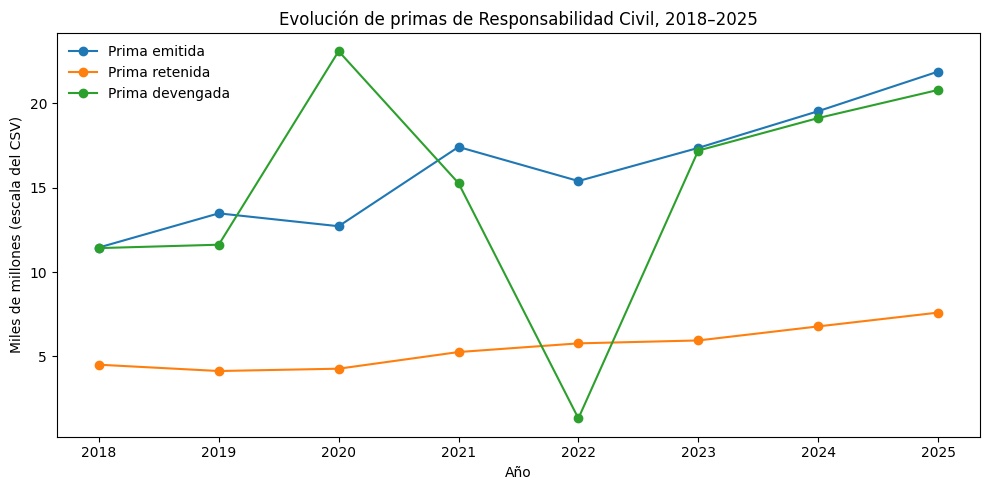

In [ ]:
# Construimos una gráfica de líneas para comparar la evolución temporal
# de las tres medidas de primas, ya que todas son variables continuas
# observadas a lo largo de varios años.

fig, ax = plt.subplots(figsize=(10, 5))

# Graficamos cada tipo de prima sobre el mismo eje para facilitar
# la comparación de sus trayectorias y diferencias de magnitud.
# Dividimos entre 1e9 para expresar los montos en miles de millones
# y hacer más legible la escala de la gráfica.

for col, nombre in [("prima_emitida", "Prima emitida"),
                    ("prima_retenida", "Prima retenida"),
                    ("prima_devengada", "Prima devengada")]:
    ax.plot(anual["anio"], anual[col] / 1e9, marker="o", label=nombre)

# Añadimos título, nombres de ejes y marcas en todos los años
# para que la gráfica sea clara e interpretable.

ax.set(title="Evolución de primas de Responsabilidad Civil, 2018–2025",
       xlabel="Año", ylabel="Miles de millones (escala del CSV)")
ax.set_xticks(anual["anio"])
ax.legend(frameon=False)

# Ajustamos la presentación, guardamos la figura para documentar
# los resultados del proyecto y finalmente la mostramos en pantalla.

fig.tight_layout()
fig.savefig(FIG / "01_evolucion_primas.png", dpi=170, bbox_inches="tight")
plt.show()

**Interpretación.** La prima emitida agregada aumentó nominalmente de 11,456.5 millones en 2018 a 21,880.7 millones en 2025 (**+91.0 %**). La prima retenida también aumentó, aunque en menor proporción (**+68.4 %**). La prima devengada no sigue un patrón similar: su pico de 2020 y su caída de 2022 requieren el diagnóstico de la sección 5. Estas series nominales no prueban crecimiento real ni identifican causas.

**Interpretación guiada:** evaluar el incremento nominal de la prima emitida. La prima devengada presenta dos años que merecen un diagnóstico separado (2020 y 2022). Evitar afirmar que las tres series se mueven de la misma manera o que sus cambios tienen una causa identificada.

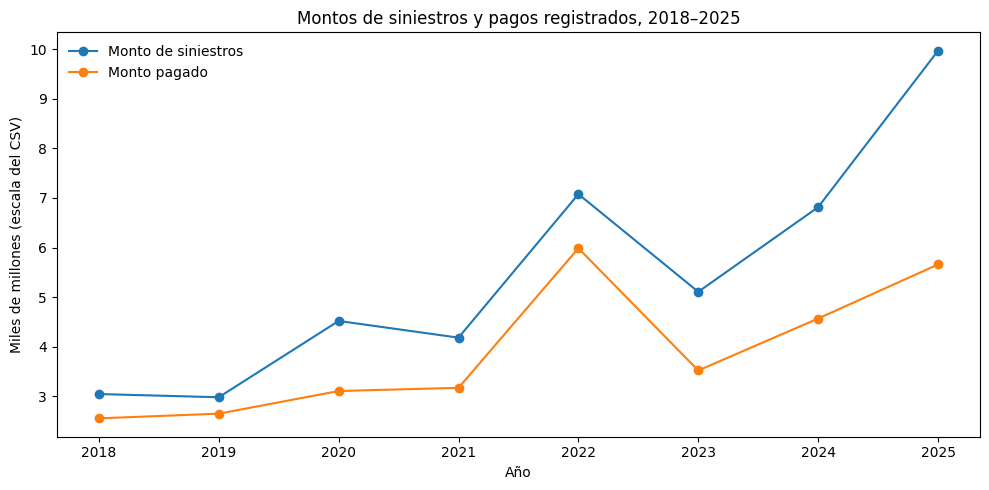

In [ ]:
# Construimos una gráfica de líneas para analizar la evolución temporal
# de los montos de siniestros y de los pagos registrados entre 2018 y 2025.

fig, ax = plt.subplots(figsize=(10, 5))

# Graficamos ambas variables en el mismo plano para comparar
# su comportamiento a lo largo del tiempo.
# Dividimos entre 1e9 para expresar los montos en miles de millones
# y facilitar la lectura de la escala.

for col, nombre in [("monto_siniestro", "Monto de siniestros"),
                    ("monto_pagado", "Monto pagado")]:
    ax.plot(anual["anio"], anual[col] / 1e9, marker="o", label=nombre)

# Añadimos título, etiquetas y marcas en cada año
# para hacer la gráfica más clara e interpretable.

ax.set(title="Montos de siniestros y pagos registrados, 2018–2025",
       xlabel="Año", ylabel="Miles de millones (escala del CSV)")
ax.set_xticks(anual["anio"])
ax.legend(frameon=False)

# Ajustamos la presentación, guardamos la visualización
# como parte de los resultados del proyecto y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "02_siniestros_y_pagos.png", dpi=170, bbox_inches="tight")
plt.show()

**Interpretación.** El monto de siniestros agregado pasó de 3,047.3 millones en 2018 a 9,965.5 millones en 2025 (**+227.0 % nominal**); el monto pagado pasó de 2,557.8 a 5,658.4 millones (**+121.2 % nominal**). Los aumentos no son equivalentes y la diferencia no debe interpretarse directamente como siniestros pendientes: podrían intervenir temporalidades y conceptos contables distintos. No son montos ajustados por inflación.

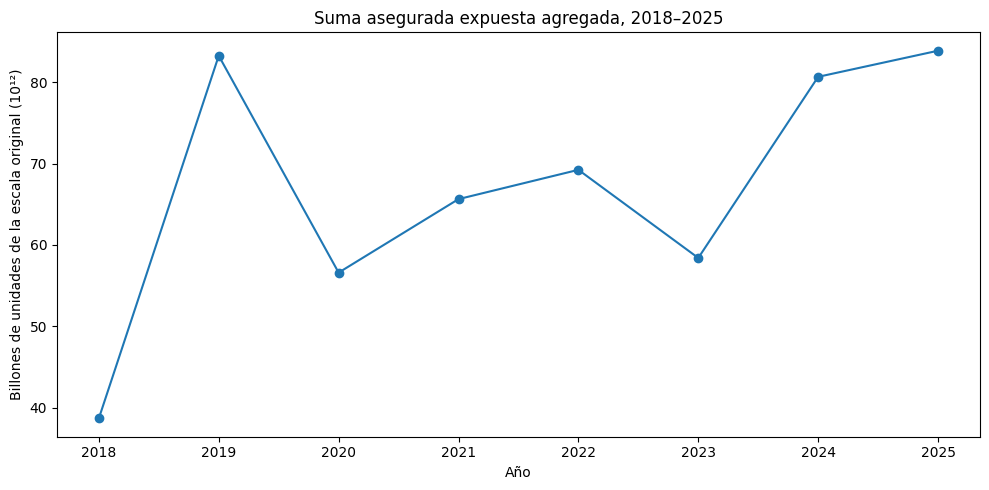

In [ ]:
# Graficamos la suma asegurada expuesta por separado debido a que
# su naturaleza y magnitud son diferentes de las primas y los siniestros.

fig, ax = plt.subplots(figsize=(10, 5))

# Dividimos entre 1e12 para expresar los montos en billones
# y facilitar la lectura de su evolución temporal.

ax.plot(anual["anio"], anual["suma_asegurada_expuesta"] / 1e12, marker="o")

# Añadimos títulos y etiquetas para facilitar la interpretación
# de los montos y del periodo analizado.

ax.set(title="Suma asegurada expuesta agregada, 2018–2025",
       xlabel="Año", ylabel="Billones de unidades de la escala original (10¹²)")
ax.set_xticks(anual["anio"])

# Ajustamos la presentación, guardamos la gráfica y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "03_suma_asegurada_expuesta.png", dpi=170, bbox_inches="tight")
plt.show()

**Interpretación.** La suma asegurada expuesta agregada registra oscilaciones considerables: aproximadamente 38.69 × 10¹² unidades en 2018, 83.26 × 10¹² en 2019 y 83.88 × 10¹² en 2025. La cifra no representa necesariamente riesgo asegurado único, porque puede agregar coberturas o límites que se repitan. Por eso evitamos dividir estos totales entre montos de siniestros como si fueran directamente comparables.

## 4. Resultados por segmento de mercado

Comparamos el volumen de primas, la suma asegurada expuesta y los montos de siniestros. Las preguntas específicas requieren estudiar no solo los montos absolutos, sino la **participación relativa de cada segmento** y cómo cambió en el tiempo. Los montos agregados permanecen provisionales hasta confirmar la unidad monetaria de reporte.


,tipo_homologado,prima_emitida,prima_retenida,monto_siniestro,monto_pagado,suma_asegurada_expuesta
158,RC Comercio,8128850189,2949393773,1.847143e+09,1.494830e+09,1.434272e+13
169,RC Industria,2776701337,637558076,5.052054e+09,2.061501e+09,4.163970e+12
175,RC Riesgos Profesionales,2598368816,1057134887,5.087274e+08,2.995122e+08,2.766191e+12
174,RC Riesgos Gubernamentales,1217393596,278519478,1.767219e+07,1.728901e+07,1.691403e+10
155,RC Aviones,975144291,153383035,2.804461e+08,1.839630e+08,2.526207e+13
165,RC Familiar,953813471,394738749,5.685453e+08,3.748812e+08,8.386227e+12
160,RC Contaminacion,783876259,154947001,3.592894e+08,9.326480e+06,8.267609e+11
161,RC Contratistas (distinto a PEMEX),692418707,316949312,8.601341e+07,8.360670e+07,3.611333e+12


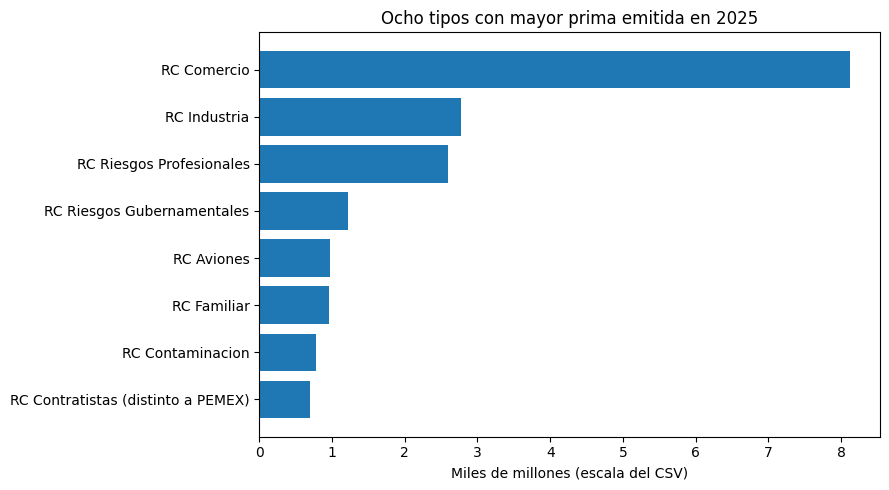

In [ ]:
# Seleccionamos los datos de 2025 y ordenamos los tipos de seguro
# de mayor a menor prima emitida para identificar los ocho segmentos
# con mayor volumen de negocio.

tipos_2025 = panel.loc[panel["anio"] == 2025].copy()
orden = tipos_2025.sort_values("prima_emitida", ascending=False).head(8)

# Mostramos las principales variables económicas de los segmentos
# seleccionados para facilitar su comparación.

display(orden[["tipo_homologado", "prima_emitida", "prima_retenida",
               "monto_siniestro", "monto_pagado", "suma_asegurada_expuesta"]])


# Utilizamos una gráfica de barras horizontales para comparar las primas
# emitidas y facilitar la lectura de los nombres de los tipos de seguro.
# Invertimos el orden para mostrar los mayores montos en la parte superior.

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(orden["tipo_homologado"][::-1], (orden["prima_emitida"] / 1e9)[::-1])

ax.set(title="Ocho tipos con mayor prima emitida en 2025",
       xlabel="Miles de millones (escala del CSV)")


# Ajustamos la presentación, guardamos la gráfica y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "04_tipos_prima_2025.png", dpi=170, bbox_inches="tight")
plt.show()

**Interpretación.** En 2025, `RC Comercio` concentra **37.2 %** de la prima emitida agregada (8,128.9 millones). El segundo tipo por prima es `RC Industria` (2,776.7 millones). Sin embargo, `RC Industria` registra el monto de siniestros más alto en 2025 (5,052.1 millones, **50.7 %** del total de ese año). El liderazgo por primas **no** implica liderazgo por siniestros; tampoco es un juicio de riesgo o rentabilidad.

### Pregunta específica 1 · Crecimiento y concentración de primas

La variación porcentual de las primas emitidas responde a **cuánto cambió cada segmento**, mientras que su participación porcentual responde a **qué importancia tiene dentro del ramo**. Para comparaciones de 2018 con 2025 se utilizan solamente segmentos presentes en ambos años y con prima inicial positiva; las categorías nuevas o ausentes no se representan como ceros.


,tipo_homologado,prima_2018,participacion_2018_pct,prima_2025,participacion_2025_pct,crecimiento_nominal_pct,cambio_participacion_pp
3,RC Comercio,2913229398,25.428585,8128850189,37.150853,179.032272,11.722268
14,RC Industria,2458044711,21.455434,2776701337,12.690211,12.963825,-8.765223
18,RC Riesgos Profesionales,2016263165,17.599273,2598368816,11.875187,28.870520,-5.724086
0,RC Aviones,767751090,6.701437,975144291,4.456650,27.013078,-2.244787
10,RC Familiar,472719852,4.126210,953813471,4.359163,101.771402,0.232953
5,RC Contaminacion,382164012,3.335779,783876259,3.582508,105.115143,0.246729
6,RC Contratistas (distinto a PEMEX),248971093,2.173184,692418707,3.164525,178.112089,0.991341
4,RC Constructores,320142461,2.794414,686620356,3.138025,114.473380,0.343610
17,RC Productos,158347153,1.382158,559176705,2.555576,253.133413,1.173417
1,RC Barcos,683042642,5.962046,556701098,2.544262,-18.496875,-3.417785


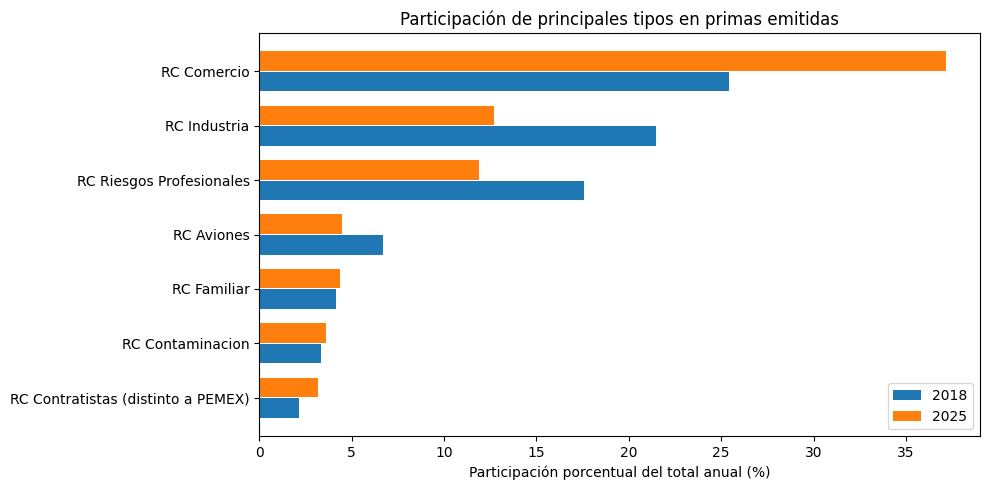

In [ ]:
# Seleccionamos las variables necesarias para analizar el crecimiento
# y la participación de cada tipo de seguro en las primas emitidas.

base_primas = panel[["anio", "tipo_homologado", "prima_emitida"]].copy()


# Calculamos el total de primas emitidas por año y la participación
# porcentual de cada tipo de seguro respecto al total anual.

base_primas["total_anual"] = base_primas.groupby("anio")["prima_emitida"].transform("sum")

base_primas["participacion_pct"] = (
    100 * base_primas["prima_emitida"] / base_primas["total_anual"]
)


# Separamos los datos de 2018 y 2025, renombrando las columnas
# para distinguir los valores del año inicial y final.

primas_2018 = base_primas.loc[
    base_primas["anio"] == 2018, ["tipo_homologado", "prima_emitida", "participacion_pct"]
].rename(columns={"prima_emitida": "prima_2018", "participacion_pct": "participacion_2018_pct"})

primas_2025 = base_primas.loc[
    base_primas["anio"] == 2025, ["tipo_homologado", "prima_emitida", "participacion_pct"]
].rename(columns={"prima_emitida": "prima_2025", "participacion_pct": "participacion_2025_pct"})


# Integramos ambos años para comparar únicamente los tipos de seguro
# presentes en los dos periodos, validando la cardinalidad de la unión.

resumen_primas = primas_2018.merge(
    primas_2025, on="tipo_homologado", how="inner", validate="one_to_one"
)


# Conservamos los segmentos con primas iniciales positivas y calculamos
# su crecimiento nominal y el cambio de participación en puntos porcentuales.

resumen_primas = resumen_primas.loc[resumen_primas["prima_2018"] > 0].copy()

resumen_primas["crecimiento_nominal_pct"] = (
    100 * (resumen_primas["prima_2025"] / resumen_primas["prima_2018"] - 1)
)

resumen_primas["cambio_participacion_pp"] = (
    resumen_primas["participacion_2025_pct"] - resumen_primas["participacion_2018_pct"]
)


# Ordenamos los segmentos por prima emitida en 2025,
# mostramos los principales resultados y exportamos la tabla.

resumen_primas = resumen_primas.sort_values("prima_2025", ascending=False)
display(resumen_primas.head(10))
resumen_primas.to_csv(OUT / "crecimiento_participacion_primas.csv", index=False)


# Construimos una gráfica de barras agrupadas para comparar
# la participación de los siete principales segmentos seleccionados
# entre 2018 y 2025.

vista = resumen_primas.head(7).iloc[::-1]
y = np.arange(len(vista))

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(y - 0.19, vista["participacion_2018_pct"], height=0.36, label="2018")
ax.barh(y + 0.19, vista["participacion_2025_pct"], height=0.36, label="2025")

ax.set_yticks(y, vista["tipo_homologado"])
ax.set(title="Participación de principales tipos en primas emitidas",
       xlabel="Participación porcentual del total anual (%)")
ax.legend()


# Ajustamos la presentación, guardamos la gráfica y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "07_concentracion_primas_2018_2025.png", dpi=150)
plt.show()

**Interpretación.** En los totales preliminares, RC Comercio pasó de aproximadamente **25.4 %** de la prima emitida en 2018 a **37.2 %** en 2025, mientras RC Industria pasó de **21.5 %** a **12.7 %**. La participación de un segmento puede disminuir aunque sus primas no necesariamente caigan: esto refleja su posición relativa frente al conjunto. Los importes y porcentajes están sujetos a verificar la comparabilidad monetaria de la publicación CNSF.


### Pregunta específica 2 · Concentración de la suma asegurada expuesta

Esta magnitud permite estudiar la **distribución de los límites expuestos reportados**, no medir directamente probabilidad de siniestro, riesgo único ni rentabilidad. Se compara la participación porcentual por tipo de seguro entre el inicio y el fin del periodo.


,tipo_homologado,participacion_2018_pct,participacion_2025_pct,cambio_participacion_pp
0,RC Aviones,16.529571,30.116245,13.586674
3,RC Comercio,12.108184,17.098716,4.990532
1,RC Barcos,24.994026,12.643057,-12.350970
10,RC Familiar,10.609626,9.997664,-0.611962
14,RC Industria,7.920671,4.964089,-2.956583
17,RC Productos,1.161828,4.665581,3.503753
6,RC Contratistas (distinto a PEMEX),3.469476,4.305261,0.835785
21,RC Viajero,9.894109,3.573922,-6.320188
18,RC Riesgos Profesionales,3.633904,3.297722,-0.336181
4,RC Constructores,2.119797,2.563941,0.444144


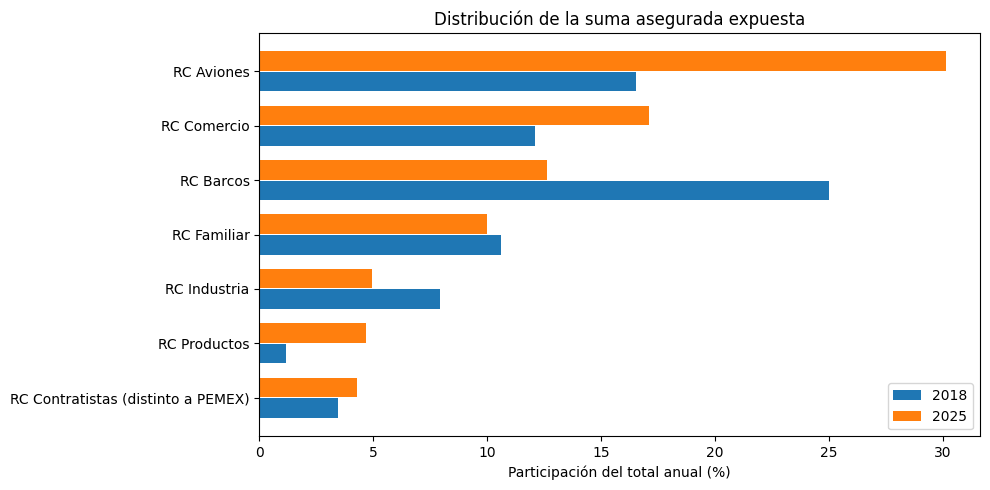

In [ ]:
# Seleccionamos las variables necesarias para analizar la distribución
# de la suma asegurada expuesta, excluyendo los registros faltantes
# sin sustituirlos por cero.

base_suma = panel[["anio", "tipo_homologado", "suma_asegurada_expuesta"]].dropna().copy()


# Calculamos la suma asegurada expuesta total por año y la participación
# porcentual de cada tipo de seguro respecto a dicho total.

base_suma["total_anual"] = (base_suma.groupby("anio")["suma_asegurada_expuesta"]
                            .transform("sum"))

base_suma["participacion_pct"] = (
    100 * base_suma["suma_asegurada_expuesta"] / base_suma["total_anual"]
)


# Separamos los datos de 2018 y 2025 para comparar la distribución
# de la exposición económica entre el año inicial y final.

suma_2018 = base_suma.loc[
    base_suma["anio"] == 2018, ["tipo_homologado", "participacion_pct"]
].rename(columns={"participacion_pct": "participacion_2018_pct"})

suma_2025 = base_suma.loc[
    base_suma["anio"] == 2025, ["tipo_homologado", "participacion_pct"]
].rename(columns={"participacion_pct": "participacion_2025_pct"})


# Integramos ambos años y calculamos el cambio de participación
# en puntos porcentuales para los tipos de seguro presentes en ambos.

resumen_suma = suma_2018.merge(
    suma_2025, on="tipo_homologado", how="inner", validate="one_to_one"
)

resumen_suma["cambio_participacion_pp"] = (
    resumen_suma["participacion_2025_pct"] - resumen_suma["participacion_2018_pct"]
)


# Ordenamos los segmentos según su participación en 2025,
# mostramos los principales resultados y exportamos la tabla.

resumen_suma = resumen_suma.sort_values("participacion_2025_pct", ascending=False)

display(resumen_suma.head(10))
resumen_suma.to_csv(OUT / "participacion_suma_asegurada.csv", index=False)


# Construimos una gráfica de barras agrupadas para comparar
# la participación de los siete principales segmentos seleccionados
# e identificar cambios en la concentración de la exposición económica.

vista = resumen_suma.head(7).iloc[::-1]
y = np.arange(len(vista))

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(y - 0.19, vista["participacion_2018_pct"], height=0.36, label="2018")
ax.barh(y + 0.19, vista["participacion_2025_pct"], height=0.36, label="2025")

ax.set_yticks(y, vista["tipo_homologado"])
ax.set(title="Distribución de la suma asegurada expuesta",
       xlabel="Participación del total anual (%)")
ax.legend()


# Ajustamos la presentación, guardamos la gráfica y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "08_concentracion_suma_2018_2025.png", dpi=150)
plt.show()

**Interpretación.** En la suma asegurada expuesta agregada, RC Aviones pasó de aproximadamente **16.5 %** en 2018 a **30.1 %** en 2025; RC Barcos redujo su participación de **25.0 %** a **12.6 %**. Estos resultados describen composición de los límites reportados, **no** diferencias de riesgo actuarial entre ramas.


### Pregunta específica 3 · Participación en primas frente a participación en siniestros

Se contrasta la participación en el total de **primas emitidas** con la participación en el total de **montos de siniestros** para 2025. Las dos participaciones se calculan respecto a los totales de **su propia fuente**, no sobre solo las categorías seleccionadas en la gráfica. La diferencia en puntos porcentuales es una descripción de concentración, **no una tasa de siniestralidad**.


,tipo_homologado,participacion_prima_pct,participacion_siniestros_pct,brecha_pp
174,RC Riesgos Gubernamentales,5.563789,0.177334,-5.386455
155,RC Aviones,4.456650,2.814177,-1.642473
160,RC Contaminacion,3.582508,3.605342,0.022834
175,RC Riesgos Profesionales,11.875187,5.104899,-6.770288
165,RC Familiar,4.359163,5.705150,1.345987
158,RC Comercio,37.150853,18.535427,-18.615426
169,RC Industria,12.690211,50.695568,38.005358


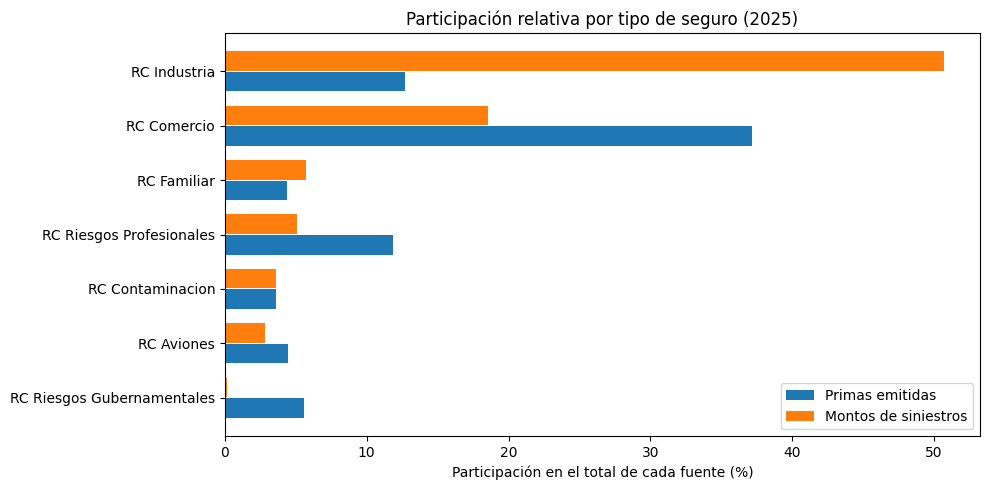

In [ ]:
# Seleccionamos los datos de 2025 para comparar la participación
# de cada tipo de seguro en las primas emitidas y los siniestros.

b25 = panel.loc[
    panel["anio"] == 2025, ["tipo_homologado", "prima_emitida", "monto_siniestro"]
].copy()


# Calculamos la participación porcentual respecto al total de cada
# variable y su diferencia en puntos porcentuales.
# Excluimos de la comparación los registros con información faltante.

b25["participacion_prima_pct"] = 100 * b25["prima_emitida"] / b25["prima_emitida"].sum()

b25["participacion_siniestros_pct"] = (
    100 * b25["monto_siniestro"] / b25["monto_siniestro"].sum(min_count=1)
)

b25["brecha_pp"] = b25["participacion_siniestros_pct"] - b25["participacion_prima_pct"]

b25_validos = b25.dropna(subset=["participacion_prima_pct", "participacion_siniestros_pct"])


# Seleccionamos los cinco tipos de seguro con mayores primas y los cinco
# con mayores montos de siniestros, evitando repetir categorías.

top_primas = b25_validos.sort_values("prima_emitida", ascending=False).head(5)
top_siniestros = b25_validos.sort_values("monto_siniestro", ascending=False).head(5)

seleccion = pd.concat([
    top_primas[["tipo_homologado"]], top_siniestros[["tipo_homologado"]]
]).drop_duplicates()


# Organizamos los segmentos seleccionados según su participación
# en los siniestros, mostramos la comparación y exportamos los resultados.

comparacion_2025 = b25_validos.loc[
    b25_validos["tipo_homologado"].isin(seleccion["tipo_homologado"])
].sort_values("participacion_siniestros_pct")

display(comparacion_2025[["tipo_homologado", "participacion_prima_pct",
                          "participacion_siniestros_pct", "brecha_pp"]])

b25.to_csv(OUT / "participaciones_primas_siniestros_2025.csv", index=False)


# Construimos una gráfica de barras agrupadas para comparar
# la importancia relativa de cada segmento en primas y siniestros.

y = np.arange(len(comparacion_2025))
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(y - 0.19, comparacion_2025["participacion_prima_pct"],
        height=0.36, label="Primas emitidas")

ax.barh(y + 0.19, comparacion_2025["participacion_siniestros_pct"],
        height=0.36, label="Montos de siniestros")

ax.set_yticks(y, comparacion_2025["tipo_homologado"])

ax.set(title="Participación relativa por tipo de seguro (2025)",
       xlabel="Participación en el total de cada fuente (%)")
ax.legend()


# Ajustamos la presentación, guardamos la gráfica y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "09_participacion_primas_siniestros_2025.png", dpi=150)
plt.show()

**Interpretación.** En 2025, RC Comercio concentra aproximadamente **37.2 % de las primas** pero **18.5 % de los montos de siniestros**, mientras RC Industria representa **12.7 % de las primas** y **50.7 % de los siniestros**. Estas diferencias permiten identificar segmentos que merecen mayor estudio, pero no demuestran que uno sea más riesgoso o menos rentable. Una tasa de siniestralidad requeriría corroborar los conceptos, periodos y unidades de los montos utilizados.


### Descripción de la dispersión entre tipos de seguro (2025)

Calculamos media, mediana, cuartiles y rango intercuartílico (RIC) de la **prima emitida por tipo de seguro**, utilizando las 24 observaciones agregadas de 2025. Esta unidad evita interpretar registros originales como pólizas individuales. Una media muy superior a la mediana indicaría asimetría por concentración en unos pocos tipos.

In [ ]:
# Seleccionamos las primas emitidas por tipo de seguro en 2025
# para conocer su distribución y las diferencias entre segmentos.

primas_tipo_2025 = tipos_2025["prima_emitida"]


# Calculamos medidas de tendencia central, dispersión y posición
# para caracterizar la distribución de las primas emitidas.

descriptivos = primas_tipo_2025.describe(percentiles=[0.25, 0.50, 0.75])

q1, q3 = primas_tipo_2025.quantile([0.25, 0.75])
ric = q3 - q1


# Mostramos los principales estadísticos para comparar el valor central
# de la distribución y conocer la dispersión del 50 % central de los datos.

print("Número de tipos:", len(primas_tipo_2025))
print("Media:", round(primas_tipo_2025.mean(), 1))
print("Mediana:", round(primas_tipo_2025.median(), 1))
print("Rango intercuartílico:", round(ric, 1))


# Presentamos y exportamos la tabla de estadística descriptiva
# para facilitar la consulta e interpretación de los resultados.

display(descriptivos.to_frame(name="prima_emitida_por_tipo"))

descriptivos.to_frame(name="prima_emitida_por_tipo").to_csv(
    OUT / "estadisticos_tipos_2025.csv")

Número de tipos: 24
Media: 911693981.8
Mediana: 354769844.5
Rango intercuartílico: 697545570.2


,prima_emitida_por_tipo
count,2.400000e+01
mean,9.116940e+08
std,1.701672e+09
min,1.552288e+06
25%,1.288150e+08
50%,3.547698e+08
75%,8.263606e+08
max,8.128850e+09


**Interpretación.** La prima emitida media por tipo de seguro en 2025 es aproximadamente 911.7 millones, frente a una mediana de 354.8 millones. La diferencia muestra una distribución muy desigual entre tipos, influida por categorías grandes como `RC Comercio`. El RIC expresa la dispersión del 50 % central sin eliminar valores extremos.

## 5. Calidad de datos, atípicos y sensibilidad

### Decisión 3 · No imputar faltantes estructurales ni reemplazar negativos por cero

Antes de 2022, `recuperacion_terceros` y `recuperacion_reaseguro` están vacías en su totalidad. Los NA no se imputan ni se reinterpretan como ceros. Por otra parte, los montos negativos pueden ser ajustes contables o reversos; **no tenemos evidencia para eliminarlos**. Se conservan y se documenta su frecuencia. Un número extremo tampoco es sinónimo automático de error.

### Evaluación de sensibilidad de la prima devengada

En 2020 aparece una observación de prima devengada inusualmente alta respecto del total anual. Calculamos un escenario **hipotético** sin esa observación para observar su influencia. La comparación no modifica el análisis principal ni el archivo original. En 2022 se cuantifica la proporción de ceros de prima devengada; no se imputa su valor.

Valor máximo: 11240210515.0 año: 2020
Participación del máximo en el total anual: 48.68 %
Ceros en prima devengada, 2022: 35898 de 103738 = 34.6 %


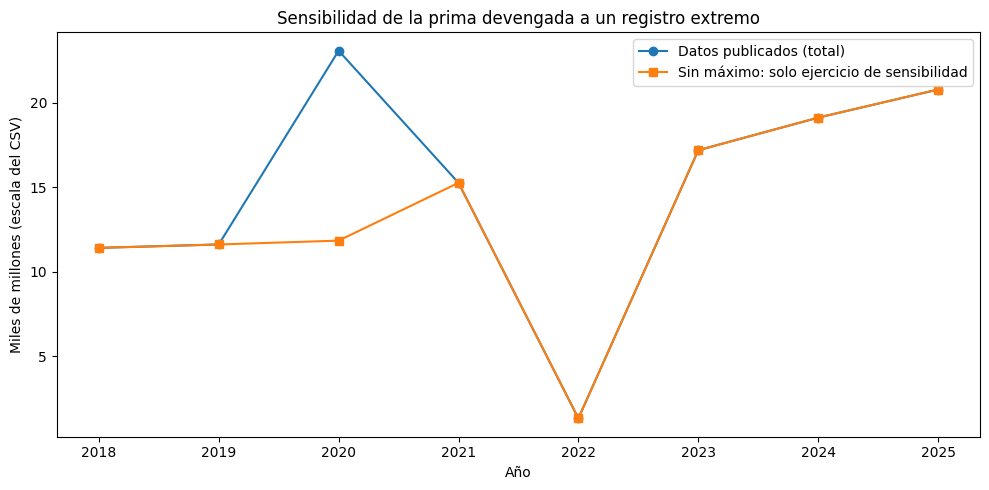

In [ ]:
# Identificamos el registro con mayor prima devengada y calculamos
# cuánto representa respecto al total del año en que se registró,
# para evaluar su influencia sobre los resultados.

em = datos["emision"]
registro_maximo = em.sort_values("prima_devengada", ascending=False).head(1)

anio_maximo = int(registro_maximo["anio"].iloc[0])
valor_maximo = float(registro_maximo["prima_devengada"].iloc[0])

base_anual = (em.groupby("anio", observed=True)["prima_devengada"]
              .sum().loc[2018:2025])

porc_maximo = 100 * valor_maximo / base_anual.loc[anio_maximo]


# Cuantificamos los registros con prima devengada igual a cero en 2022
# para evaluar su presencia y facilitar la interpretación del total anual.

cero_2022 = int(((em["anio"] == 2022) & (em["prima_devengada"] == 0)).sum())
filas_2022 = int((em["anio"] == 2022).sum())

print("Valor máximo:", valor_maximo, "año:", anio_maximo)
print("Participación del máximo en el total anual:", round(porc_maximo, 2), "%")
print("Ceros en prima devengada, 2022:", cero_2022, "de", filas_2022,
      "=", round(100 * cero_2022 / filas_2022, 2), "%")


# Construimos dos escenarios para evaluar la influencia del valor extremo:
# uno con los montos originales y otro excluyendo únicamente dicho registro.
# Esta comparación no modifica los datos originales.

sensibilidad = pd.DataFrame({
    "anio": base_anual.index,
    "original": base_anual.values,
    "sin_maximo_2020_solo_comparacion": base_anual.values.copy()
})

sensibilidad.loc[sensibilidad["anio"] == anio_maximo,
                 "sin_maximo_2020_solo_comparacion"] -= valor_maximo

sensibilidad.to_csv(OUT / "sensibilidad_prima_devengada.csv", index=False)


# Graficamos ambos escenarios para observar cuánto cambia
# la evolución temporal de la prima devengada al excluir el valor extremo.

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(sensibilidad["anio"], sensibilidad["original"] / 1e9,
        marker="o", label="Datos publicados (total)")

ax.plot(sensibilidad["anio"], sensibilidad["sin_maximo_2020_solo_comparacion"] / 1e9,
        marker="s", label="Sin máximo: solo ejercicio de sensibilidad")

ax.set(title="Sensibilidad de la prima devengada a un registro extremo",
       xlabel="Año", ylabel="Miles de millones (escala del CSV)")

ax.set_xticks(sensibilidad["anio"])
ax.legend()


# Ajustamos la presentación, guardamos la gráfica y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "05_sensibilidad_devengada.png", dpi=170, bbox_inches="tight")
plt.show()

**Interpretación.** El máximo individual de prima devengada (11,240.2 millones) equivale al **48.68 %** del agregado de 2020. Quitar únicamente ese registro en un escenario de sensibilidad reduce artificialmente el total del año de 23,090.6 a 11,850.4 millones; **el escenario no es una corrección del dato**. En 2022, 35,898 de 103,738 registros (**34.60 %**) tienen prima devengada cero, pero esta frecuencia no explica por sí sola por qué el agregado del año es bajo. Hace falta validación técnica del origen.

## 6. Análisis metodológico complementario: asociación entre montos (2025)

Para examinar si los tipos con mayores primas también registran mayores siniestros, analizamos los datos de **un solo año**, evitando mezclar variación temporal con diferencias de tamaño. Mostramos Pearson (asociación lineal) y Spearman (rangos). Un coeficiente no demuestra causalidad ni permite inferir un índice actuarial de siniestralidad. Además, los tipos no son observaciones estadísticamente independientes en sentido causal.

Tipos con datos presentes en ambas fuentes: 23
Pearson=0.549; Spearman=0.764


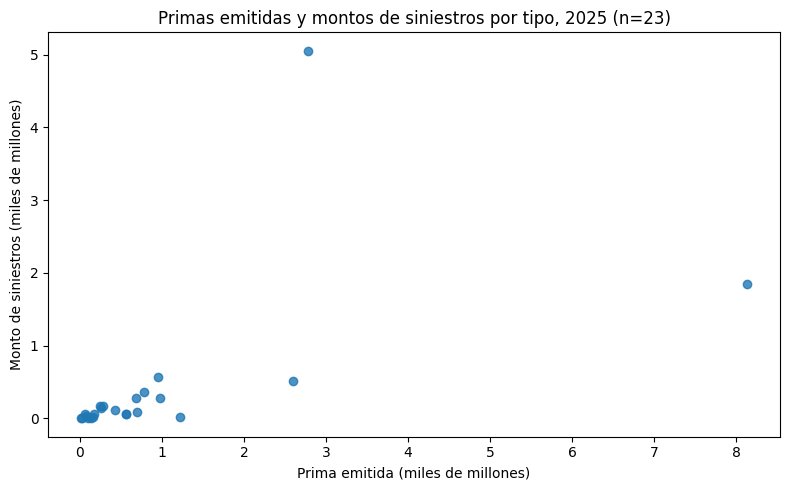

In [ ]:
# Seleccionamos las primas emitidas y los montos de siniestros de 2025.
# Excluimos los registros con información faltante para analizar
# únicamente los tipos de seguro con datos en ambas variables.

asociacion = tipos_2025[["tipo_homologado", "prima_emitida", "monto_siniestro"]].dropna()


# Calculamos los coeficientes de Pearson y Spearman para evaluar
# la dirección y fuerza de la asociación lineal y monótona, respectivamente.

pearson = asociacion["prima_emitida"].corr(asociacion["monto_siniestro"], method="pearson")
spearman = asociacion["prima_emitida"].corr(asociacion["monto_siniestro"], method="spearman")

print(f"Tipos con datos presentes en ambas fuentes: {len(asociacion)}")
print(f"Pearson={pearson:.3f}; Spearman={spearman:.3f}")


# Construimos un diagrama de dispersión para visualizar la relación
# entre ambas variables e identificar patrones y posibles valores atípicos.
# Cada punto representa un tipo de seguro.

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(asociacion["prima_emitida"] / 1e9,
           asociacion["monto_siniestro"] / 1e9, alpha=0.8)

ax.set(title=f"Primas emitidas y montos de siniestros por tipo, 2025 (n={len(asociacion)})",
       xlabel="Prima emitida (miles de millones)",
       ylabel="Monto de siniestros (miles de millones)")


# Ajustamos la presentación, guardamos la gráfica y la mostramos.

fig.tight_layout()
fig.savefig(FIG / "06_asociacion_primas_siniestros_2025.png", dpi=170, bbox_inches="tight")
plt.show()

**Interpretación.** Entre los 23 tipos con observaciones presentes en ambas fuentes en 2025, la correlación de **Pearson es 0.549** y la de **Spearman es 0.764**. El mayor valor de Spearman indica que la ordenación de tipos según los dos montos se asemeja más de lo que sugiere una relación lineal estricta, susceptible a valores extremos. Estos coeficientes solo describen asociación en el corte de 2025; no implican causalidad ni controlan factores como tamaño de cartera o mezcla de productos. Se excluye la combinación sin registro de siniestros, sin asignarle valor cero.

## 7. Bitácora de decisiones y comprobaciones finales

| Decisión | Problema | Tratamiento | Consecuencia y límite |
|---|---|---|---|
| 1. Homologar nombres de tipos | Abreviaturas y nombres históricos de tipos de seguro | Diccionario explícito, `apply()` y campo original conservado | Evita fragmentación; revisar equivalencias de forma sustantiva. |
| 2. Agregar antes de unir | Diferente granularidad y más dimensiones en cada fuente | Agrupación independiente por año × tipo, `validate='one_to_one'` y sumas invariantes | Evita duplicación artificial; reduce detalle de giro/entidad/cobertura. |
| 3. Periodo común 2018–2025 | Archivo 34 no contiene 2015–2017 | Selección explícita, originales intactos | Comparaciones consistentes; no describen todo el periodo de archivos 33 y 35. |
| 4. Conservar NA, negativos y extremos | Faltantes pre-2022, valores negativos, observación extrema 2020 | No imputar/borrar; comparar escenario de sensibilidad | Mantiene trazabilidad; requiere investigación contable adicional. |

**Comprobación:** con los valores publicados, las uniones no cambian los totales de cada fuente ni multiplican la unidad final. La ausencia en la fuente de siniestros permanece como `NaN`, no como cero. Los resultados no están corregidos por inflación.

In [ ]:
# Realizamos validaciones finales para comprobar que la base integrada
# conserva una fila por año y tipo de seguro y abarca el periodo establecido.

assert not panel.duplicated(["anio", "tipo_homologado"]).any()
assert panel["anio"].between(2018, 2025).all()
assert len(anual) == 8


# Verificamos que la prima emitida no presente valores faltantes
# y que se conserve el número total de registros de las bases originales.

assert datos["emision"]["prima_emitida"].notna().all()
assert sum(len(tabla) for tabla in datos.values()) == 2_183_493


# Confirmamos que las validaciones se superaron e indicamos
# la ubicación de los resultados generados durante el análisis.

print("Validaciones básicas superadas.")
print("Revise los resultados en data/processed/ y las nueve gráficas en figures/.")

Validaciones básicas superadas.
Revise los resultados en data/processed/ y las nueve gráficas en figures/.


## 8. Conclusiones y limitaciones

1. Las series de primas, sumas aseguradas y siniestros permiten estudiar tendencias y composición **nominal** del ramo, pero las magnitudes tienen significados distintos.
2. La prima devengada merece tratamiento particular: un registro extremo en 2020 y una proporción alta de ceros en 2022 condicionan la interpretación de esa variable.
3. La homologación de tipos de seguro y la agregación **antes** de integrar fuentes son decisiones fundamentales para evitar fragmentación y duplicación de montos.
4. La ausencia de recuperaciones antes de 2022 no debe confundirse con recuperaciones nulas. Los negativos se mantienen porque no están identificados como errores.
5. El análisis no controla inflación, denominación monetaria o cambios regulatorios/metodológicos; tampoco permite concluir causalidad, rentabilidad ni siniestralidad actuarial.


### Referencias y procedencia
- [CNSF, datos abiertos](https://www.cnsf.gob.mx/Transparencia/Paginas/DatosAbiertos.aspx).
- [Archivo 33 — Emisión](https://www.cnsf.gob.mx/Transparencia/DGDI/33%20Informacion%20estadistica%20del%20sector%20asegurador_Responsabilidad%20Civil_Emision.csv).
- [Archivo 34 — Suma asegurada](https://www.cnsf.gob.mx/Transparencia/DGDI/34%20Informacion%20estadistica%20del%20sector%20asegurador_Responsabilidad%20Civil_Suma%20Asegurada.csv).
- [Archivo 35 — Siniestros](https://www.cnsf.gob.mx/Transparencia/DGDI/35%20Informacion%20estadistica%20del%20sector%20asegurador_Responsabilidad%20Civil_Siniestros.csv).